# 03 — Ingeniería de variables

## Objetivo

Construir el dataset de modelado: una fila por mapa con variables que describan a los dos
equipos **usando únicamente información anterior al mapa**, más la variable objetivo.

El cuadernillo responde tres preguntas:

1. ¿Por qué no se pueden usar directamente las estadísticas del dataset? (fuga de datos)
2. ¿Cómo se convierte el rendimiento pasado de un equipo en variables?
3. ¿Cómo se comprueba que ninguna variable está viendo el futuro?

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

from src.config import INTERIM_DIR, PROCESSED_DIR, load_config
from src.data_loading import load_table
from src.features import FEATURES, PLAYER_STATS, build_dataset, team_map_stats
from src.plotting import set_style, save_fig

set_style()
config = load_config()
maps = pd.read_csv(INTERIM_DIR / "maps.csv")
overview = load_table("matches/overview.csv")
eco_stats = load_table("matches/eco_stats.csv")
draft = load_table("matches/draft_phase.csv")
print(maps.shape, overview.shape, eco_stats.shape, draft.shape)

(27368, 14) (1149895, 22) (297920, 10) (20352, 8)


## 1. El problema: la fuga de datos

`overview.csv` tiene el rating, el ACS (puntaje de combate) y los *kills* de cada jugador en
cada mapa. Es tentador usarlos como variables. Para ver qué pasaría, se construye una tabla
con lo que hizo cada equipo **en cada mapa** y se mide qué tan bien el ACS del propio mapa
"predice" a su ganador.

`team_map_stats()` (en `src/features.py`) arma esa tabla: dos filas por mapa, una por equipo,
promediando las estadísticas de sus cinco jugadores. Solo toma las filas `Side = both` y
descarta el agregado `All Maps`, para no contar nada dos veces.

In [2]:
long = team_map_stats(maps, overview, eco_stats)
print(long.shape)
long.head(4)

(54736, 15)


,game_id,match_id,stage_block,map,side,team,opponent,won,round_diff,rating,acs,adr,kast,fkd,pistol_won
0,14718,8757,8757,Bind,a,Kaos Latin Gamers,NoBordeR,1,10,NaN,269.0,162.2,NaN,1.2,NaN
1,14718,8757,8757,Bind,b,NoBordeR,Kaos Latin Gamers,0,-10,NaN,150.0,92.2,NaN,-1.2,NaN
2,14719,8757,8757,Haven,a,Kaos Latin Gamers,NoBordeR,1,12,NaN,262.6,152.0,NaN,1.6,NaN
3,14719,8757,8757,Haven,b,NoBordeR,Kaos Latin Gamers,0,-12,NaN,146.8,103.6,NaN,-1.6,NaN


In [3]:
same_map = long.pivot(index="game_id", columns="side", values="acs")
same_map["acs_diff"] = same_map["a"] - same_map["b"]
same_map = same_map.join(maps.set_index("game_id")["team_a_win"]).dropna()

leak_auc = roc_auc_score(same_map["team_a_win"], same_map["acs_diff"])
leak_acc = ((same_map["acs_diff"] > 0) == (same_map["team_a_win"] == 1)).mean()
print(f"AUC del ACS del mismo mapa: {leak_auc:.3f}")
print(f"'Gana el equipo con más ACS en ese mapa' acierta el {leak_acc:.1%}")

AUC del ACS del mismo mapa: 0.986
'Gana el equipo con más ACS en ese mapa' acierta el 93.6%


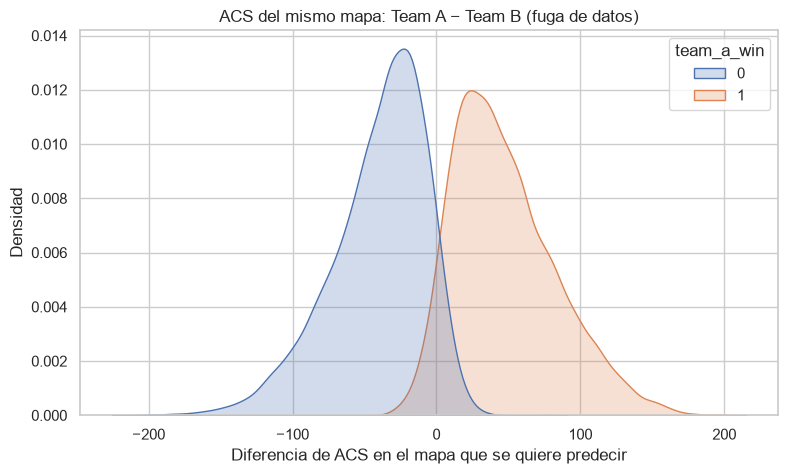

In [4]:
fig, ax = plt.subplots()
sns.kdeplot(data=same_map, x="acs_diff", hue="team_a_win", fill=True, common_norm=False, ax=ax)
ax.set(title="ACS del mismo mapa: Team A − Team B (fuga de datos)",
       xlabel="Diferencia de ACS en el mapa que se quiere predecir", ylabel="Densidad")
save_fig("03_fuga_acs_mismo_mapa")
plt.show()

Con una sola variable se "acierta" casi siempre. No es que el modelo sea bueno: el ACS se
calcula con lo que pasó **durante** el mapa, así que es una consecuencia del resultado, no
una causa. Un modelo así sería inútil en la práctica, porque antes del partido ese dato no existe.

**Regla del proyecto:** las estadísticas de un mapa solo pueden usarse para describir mapas
*posteriores*.

## 2. De estadísticas por mapa a historial por equipo

La idea es reemplazar "lo que el equipo hizo en este mapa" por "lo que el equipo venía
haciendo antes de este mapa". Para cada equipo se recorren sus mapas en orden y se acumula su
rendimiento.

Hay una restricción adicional descubierta en el cuadernillo 01: los IDs no ordenan los
partidos dentro de una misma etapa. Por eso el historial de un mapa incluye solo los mapas de
**etapas anteriores** (`stage_block` menor):

```
Etapa 1 (grupos)        Etapa 2 (playoffs)        Etapa 3 (siguiente torneo)
 mapa mapa mapa   →      mapa mapa mapa     →      mapa  ← se predice
 └───────── historial utilizable ─────────┘        (los demás mapas de la etapa 3 no se usan)
```

Variables que se calculan para cada equipo y luego se expresan como **diferencia Team A − Team B**:

| Variable | Qué mide |
|---|---|
| `diff_winrate` | Proporción de mapas ganados en todo su historial |
| `diff_winrate_recent` | Proporción de mapas ganados en sus últimos 10 mapas (forma reciente) |
| `diff_winrate_map` | Proporción de victorias en **este** mapa |
| `diff_maps_played` | Mapas jugados (experiencia) |
| `diff_maps_played_map` | Mapas jugados en **este** mapa |
| `diff_round_diff` | Diferencia de rondas promedio (con qué margen gana o pierde) |
| `diff_rating`, `diff_acs`, `diff_adr`, `diff_kast` | Promedio histórico del nivel individual de sus jugadores |
| `diff_fkd` | Duelos de apertura: primeras bajas menos primeras muertes |
| `diff_pistol` | Rondas de pistola ganadas por mapa |

Variables del enfrentamiento (no son diferencias):

| Variable | Qué mide |
|---|---|
| `h2h_winrate_a`, `h2h_games` | Resultado de los enfrentamientos previos entre ambos equipos, y cuántos hubo |
| `a_picked_map` | 1 si Team A eligió el mapa, −1 si lo eligió Team B, 0 si no lo eligió ninguno (mapa decisivo) |
| `min_maps_played` | Mapas previos del equipo con **menos** historial: cuánta evidencia respalda la fila |

Se usan diferencias porque lo que importa no es qué tan bueno es un equipo en términos
absolutos, sino qué tan bueno es **comparado con su rival**. Además reduce a la mitad el
número de variables.

Todo el cálculo está en `build_dataset()`.

In [5]:
dataset = build_dataset(maps, overview, eco_stats, draft,
                        window=config["recent_window"], seed=config["seed"])
print(dataset.shape)
dataset.tail(3).T

(27368, 24)


,27365,27366,27367
game_id,270764,270765,270766
match_id,684619,684619,684619
stage_block,684610,684610,684610
year,2026,2026,2026
map,Lotus,Haven,Fracture
team_a,FUT Esports,FUT Esports,FUT Esports
team_b,Mega Minors,Mega Minors,Mega Minors
team_a_win,0,1,1
diff_winrate,-0.031333,-0.031333,-0.031333
diff_winrate_recent,-0.4,-0.4,-0.4


## 3. Comprobación a mano sobre un mapa real

Para confiar en las variables no basta con que el código corra. Se toma un mapa conocido —
el primer mapa de la *Lower Final* de Valorant Champions 2024, LEVIATÁN contra Team Heretics
— y se recalcula `diff_winrate` paso a paso, sin usar `build_dataset`.

In [6]:
example = dataset[(dataset["match_id"] == 378836)].iloc[0]
example[["game_id", "stage_block", "map", "team_a", "team_b", "diff_winrate", "diff_maps_played", "min_maps_played"]]

game_id                    180455
stage_block                378822
map                        Icebox
team_a              Team Heretics
team_b                   LEVIATÁN
diff_winrate             0.056242
diff_maps_played            -12.0
min_maps_played             210.0
Name: 25206, dtype: object

In [7]:
def prior_record(team, stage_block):
    """Mapas del equipo en etapas anteriores a `stage_block`."""
    played = maps[((maps["team_a"] == team) | (maps["team_b"] == team)) & (maps["stage_block"] < stage_block)]
    won = ((played["team_a"] == team) & (played["team_a_win"] == 1)) | \
          ((played["team_b"] == team) & (played["team_a_win"] == 0))
    return len(played), won.mean(), played["match_id"].max()

n_a, winrate_a, last_a = prior_record(example["team_a"], example["stage_block"])
n_b, winrate_b, last_b = prior_record(example["team_b"], example["stage_block"])
print(f"{example['team_a']}: {n_a} mapas previos, winrate {winrate_a:.4f}")
print(f"{example['team_b']}: {n_b} mapas previos, winrate {winrate_b:.4f}")
print(f"Diferencia a mano:        {winrate_a - winrate_b:.6f}")
print(f"Diferencia en el dataset: {example['diff_winrate']:.6f}")
print(f"Último partido usado: {max(last_a, last_b)}  |  primer partido de esta etapa: {example['stage_block']}")

assert np.isclose(winrate_a - winrate_b, example["diff_winrate"])
assert n_a - n_b == example["diff_maps_played"]
assert max(last_a, last_b) < example["stage_block"]

Team Heretics: 210 mapas previos, winrate 0.6238
LEVIATÁN: 222 mapas previos, winrate 0.5676
Diferencia a mano:        0.056242
Diferencia en el dataset: 0.056242
Último partido usado: 378672  |  primer partido de esta etapa: 378822


El cálculo a mano coincide con el dataset, y el último partido que entra en el historial es
anterior al inicio de los *playoffs*: ni la final ni ningún otro partido de esa etapa se usan.

Además de esta comprobación puntual, `tests/test_features.py` verifica de forma automática
las propiedades que garantizan que no hay fuga:

- cambiar los resultados de una etapa no altera ninguna variable de esa etapa;
- eliminar mapas futuros no altera las variables de los mapas anteriores;
- en la primera etapa de un equipo todas sus variables quedan vacías;
- intercambiar Team A y Team B invierte el signo de las diferencias y el objetivo.

In [8]:
import subprocess
result = subprocess.run([sys.executable, "../tests/test_features.py"], capture_output=True, text=True)
print(result.stdout or result.stderr)

OK test_no_leakage_from_own_stage
OK test_future_does_not_affect_past
OK test_first_stage_has_no_history
OK test_known_values
OK test_swap_symmetry
OK test_missing_side_tables_keep_row
OK test_to_number



## 4. Intercambio aleatorio de Team A y Team B

En el cuadernillo 02 se vio que Team A suele ser el favorito. `build_dataset` intercambia los
dos equipos en una mitad aleatoria de las filas (con semilla fija, para que sea reproducible):
se invierten los nombres, el signo de las diferencias y el objetivo. Se verifica el efecto.

In [9]:
check = maps.groupby("year")["team_a_win"].mean().to_frame("antes")
check["despues"] = dataset.groupby("year")["team_a_win"].mean()
print(f"Global: antes {maps['team_a_win'].mean():.3f} → después {dataset['team_a_win'].mean():.3f}")
check.round(3)

Global: antes 0.573 → después 0.501


,antes,despues
year,,
2021,0.583,0.500
2022,0.587,0.501
2023,0.511,0.511
2024,0.519,0.505
2025,0.511,0.498
2026,0.472,0.503


El objetivo queda en 50 % en todos los años. A partir de aquí, la línea base de "predecir
siempre la clase mayoritaria" vale 50 %, y cualquier acierto por encima se debe a las variables.

## 5. Valores faltantes

Una variable queda vacía cuando no hay con qué calcularla: equipos sin mapas en etapas
anteriores, estadísticas que la web no registró, o partidos sin datos de vetos.

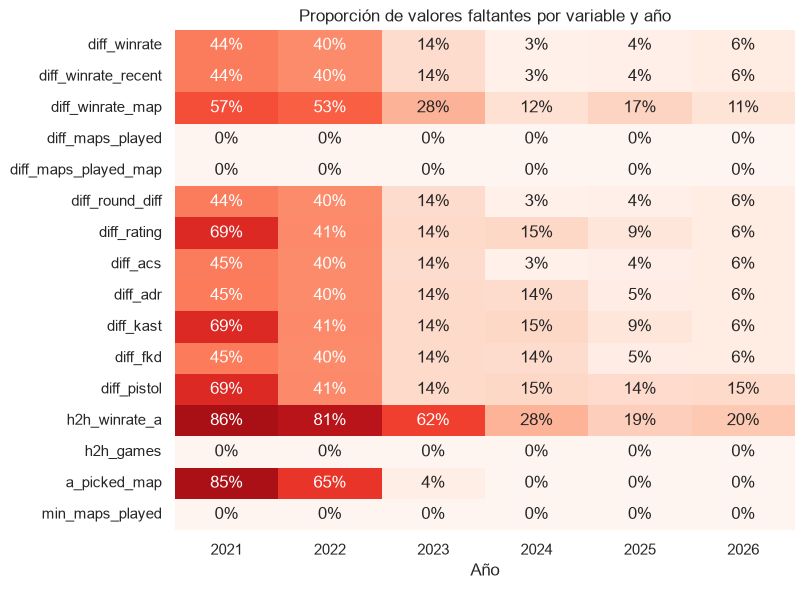

In [10]:
missing = dataset[FEATURES].isna().groupby(dataset["year"]).mean().T
plt.figure(figsize=(8, 6.5))
sns.heatmap(missing, annot=True, fmt=".0%", cmap="Reds", cbar=False, vmin=0, vmax=1)
plt.title("Proporción de valores faltantes por variable y año")
plt.xlabel("Año"); plt.ylabel("")
save_fig("03_valores_faltantes")
plt.show()

Lectura del gráfico:

- **Las variables de rendimiento** (`diff_winrate`, `diff_round_diff`, `diff_acs`…) faltan en
  40–45 % de los mapas de 2021–2022 y en menos del 15 % desde 2023. Es el costo, ya medido en
  el cuadernillo 01, de los equipos que solo jugaron un clasificatorio abierto.
- **`diff_rating`, `diff_kast` y `diff_pistol`** faltan más en 2021 (69 %): vlr.gg no
  registraba esas estadísticas en muchos partidos de ese año.
- **`diff_winrate_map`** falta más que el winrate general, porque exige que *ambos* equipos
  hayan jugado antes ese mapa concreto.
- **`h2h_winrate_a`** falta en la mayoría de las filas: casi todos los enfrentamientos son la
  primera vez que esos dos equipos se cruzan. Solo desde 2024, con ligas de equipos fijos,
  hay historial directo en el 70–80 % de los mapas.
- **`a_picked_map`** casi no existe en 2021 (85 % vacío) y está completa desde 2024.
- Los conteos (`diff_maps_played`, `h2h_games`, `min_maps_played`) nunca faltan: sin historial valen 0.

**Decisión sobre los faltantes:** no se rellenan aquí. Un valor vacío significa "no hay
información", que es distinto de "la diferencia es cero"; rellenar con 0 mezclaría ambos casos.
Se dejan como nulos y cada modelo los tratará de la forma que le convenga (cuadernillo 05).
No se eliminan filas: `min_maps_played` permite filtrar o analizar por cantidad de evidencia más adelante.

## 6. Primer vistazo: ¿las variables separan a ganadores de perdedores?

Sin entrar todavía en la selección (cuadernillo 04), se revisa que las variables principales
se comporten como se espera: valores positivos (ventaja de Team A) deberían asociarse a
victorias de Team A.

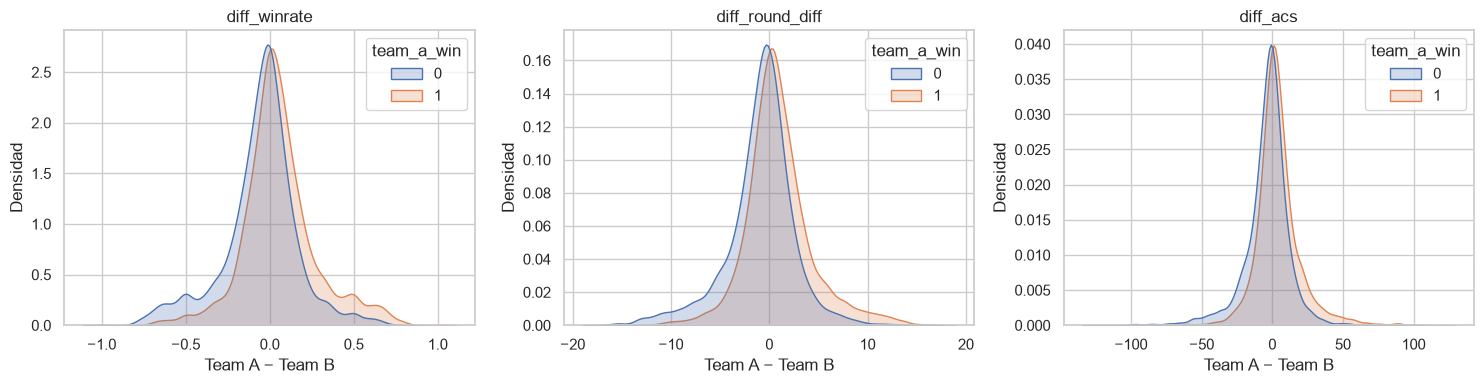

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["diff_winrate", "diff_round_diff", "diff_acs"]):
    sns.kdeplot(data=dataset, x=col, hue="team_a_win", fill=True, common_norm=False, ax=ax)
    ax.set(title=col, xlabel="Team A − Team B", ylabel="Densidad")
plt.tight_layout()
save_fig("03_distribucion_variables_principales")
plt.show()

Las curvas de ganadores y perdedores están desplazadas en el sentido esperado, pero se
solapan mucho. Es exactamente la diferencia con el gráfico de la sección 1: allí las curvas
casi no se tocaban porque la variable *era* el resultado; aquí la señal es real pero modesta,
como corresponde a información previa al partido.

## 7. Guardar el dataset

In [12]:
dataset.to_csv(PROCESSED_DIR / "dataset.csv", index=False, float_format="%.5f")
print("Guardado:", PROCESSED_DIR / "dataset.csv", dataset.shape)
dataset[FEATURES].describe().T[["count", "mean", "std", "min", "max"]].round(2)

Guardado: C:\Users\JH\Hull\Trabajos U\S7 Ciencia de Datos\Proyecto\data\processed\dataset.csv (27368, 24)


,count,mean,std,min,max
diff_winrate,17202.0,0.00,0.23,-1.00,1.00
diff_winrate_recent,17202.0,0.00,0.27,-1.00,1.00
diff_winrate_map,13718.0,-0.00,0.37,-1.00,1.00
diff_maps_played,27368.0,0.08,61.87,-494.00,494.00
diff_maps_played_map,27368.0,0.01,9.17,-75.00,76.00
diff_round_diff,17202.0,0.00,3.64,-17.25,17.25
diff_rating,13379.0,0.00,0.13,-0.87,0.87
diff_acs,17180.0,0.08,16.96,-126.31,121.57
diff_adr,17023.0,0.05,10.76,-79.98,79.84
diff_kast,13379.0,0.06,5.73,-40.57,40.57


## Conclusiones

1. **La fuga de datos es real y enorme:** la diferencia de ACS del propio mapa "predice" al
   ganador con AUC 0.986 y 93.6 % de acierto. Por eso ninguna estadística del mapa que se
   predice entra al dataset.
2. **Dataset construido:** 27 368 mapas × 16 variables, guardado en
   `data/processed/dataset.csv`. Doce variables son diferencias Team A − Team B de rendimiento
   histórico; cuatro describen el enfrentamiento (historial directo, quién eligió el mapa y
   cuánta evidencia hay).
3. **Sin fuga, comprobado de dos formas:** a mano sobre la *Lower Final* de Champions 2024
   (el valor coincide y el último partido usado es anterior a la etapa) y con siete pruebas
   automáticas en `tests/test_features.py`.
4. **Objetivo balanceado:** tras intercambiar Team A y Team B al azar, `team_a_win` pasa de
   57.3 % a 50.1 %, y queda cerca del 50 % en todos los años.
5. **Los faltantes tienen significado y no se rellenan aquí:** las variables de rendimiento
   faltan en 40–45 % de los mapas de 2021–2022 (equipos sin etapas previas) y en menos del
   15 % desde 2023. `h2h_winrate_a` y `a_picked_map` son las de peor cobertura.
6. **La señal existe pero es modesta:** las distribuciones de ganadores y perdedores se
   desplazan en el sentido esperado y se solapan mucho. Es lo normal con información previa al partido.
7. **Limitación asumida:** el historial se agrupa por nombre de equipo, así que no reacciona
   a cambios de plantilla; un equipo que renueva sus cinco jugadores conserva su historial.

**Siguiente paso (cuadernillo 04):** medir cuánto aporta cada variable, detectar las
redundantes y decidir el conjunto final.